In [1]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
from main import SingleParticleIsing

matplotlib.rcParams['text.usetex'] = False

In [2]:
def ket_to_dm(ket: np.ndarray) -> np.ndarray:
	return np.outer(ket.conj().T, ket)

In [3]:
h = 1.2
J_0 = 1.0

N = 100
neighbour_range = 1
alpha = 1
J_list = [1 / (2 * (n + 1) ** alpha) for n in range(neighbour_range)]
t_list = np.linspace(0, 2 / 3 * N, 1000)

model = SingleParticleIsing(h, J_0, N, J_list, t_list)

In [4]:
# Prepare operators
E_t_0 = np.identity(2)
E_t_1 = X = np.array([[0, 1], [1, 0]])
E_t_2 = np.array([[0, -1], [1, 0]])
E_t_3 = np.array([[1, 0], [0, -1]])
E_t_list = [E_t_0, E_t_1, E_t_2, E_t_3]

In [35]:
# # Prepare states
# state_1 = ket_to_dm(np.array([1, 0]))
# state_2 = ket_to_dm(np.array([0, 1]))
# state_3 = ket_to_dm(np.array([1 / np.sqrt(2), 1 / np.sqrt(2)]))
# state_4 = ket_to_dm(np.array([1 / np.sqrt(2), 1j / np.sqrt(2)]))

In [5]:
# # Get density matrices
# rho_1_list = model.evolution_func(state_1)
# rho_4_list = model.evolution_func(state_2)
# rho_2_list = model.evolution_func(state_3) - 1j * model.evolution_func(state_4) - (1 - 1j) * (rho_1_list + rho_4_list) / 2
# rho_3_list = model.evolution_func(state_3) + 1j * model.evolution_func(state_4) - (1 + 1j) * (rho_1_list + rho_4_list) / 2

# Get density matrices
rho_1_list = model.evolution_func(np.array([[1, 0], [0, 0]]))
rho_2_list = model.evolution_func(np.array([[0, 1], [0, 0]]))
rho_3_list = model.evolution_func(np.array([[0, 0], [1, 0]]))
rho_4_list = model.evolution_func(np.array([[0, 0], [0, 1]]))

In [6]:
lmbda = np.block([[np.identity(2), X], [X, -np.identity(2)]]) / 2

chi_list = []
for rho_1, rho_2, rho_3, rho_4 in zip(rho_1_list, rho_2_list, rho_3_list, rho_4_list):
	chi_list.append(lmbda @ np.block([[rho_1, rho_2], [rho_3, rho_4]]) @ lmbda)
chi_list = np.array(chi_list)

In [38]:
theta = np.random.uniform(0, 2 * np.pi)
phi = np.random.uniform(0, 2 * np.pi)
test_state = ket_to_dm(np.array([np.cos(theta / 2), np.exp(1j * phi) * np.sin(theta / 2)]))
test_state

array([[ 0.81460658+0.00000000e+00j, -0.37943945-8.39547971e-02j],
       [-0.37943945+8.39547971e-02j,  0.18539342+2.33166111e-18j]])

In [39]:
rho_list = model.evolution_func(test_state)
rho_list[-1]

array([[ 0.87337552+7.39126922e-19j, -0.31358418-6.93836566e-02j],
       [-0.31358418+6.93836566e-02j,  0.12662448+1.59253419e-18j]])

In [40]:
test_rho = np.zeros((2, 2), dtype=np.complex128)
for m, E_t_m in enumerate(E_t_list):
	for n, E_t_n in enumerate(E_t_list):
		test_rho += (E_t_m @ test_state @ E_t_n.T) * chi_list[-1][m, n]
test_rho

array([[ 0.87337552+7.39126922e-19j, -0.31358418-6.93836566e-02j],
       [-0.31358418+6.93836566e-02j,  0.12662448+1.59253419e-18j]])

In [20]:
A_list = []
for chi in chi_list:
	E_list = []
	d, U = np.linalg.eigh(chi)
	d[d < 0] = 0
	for i in range(len(E_t_list)):
		E_list.append(np.sqrt(d[i]) * sum(U[j, i].conj() * E_t_list[j] for j in range(len(E_t_list))))
	A_list.append(sum(np.kron(E, E.conj()) for E in E_list))
A_list = np.array(A_list)

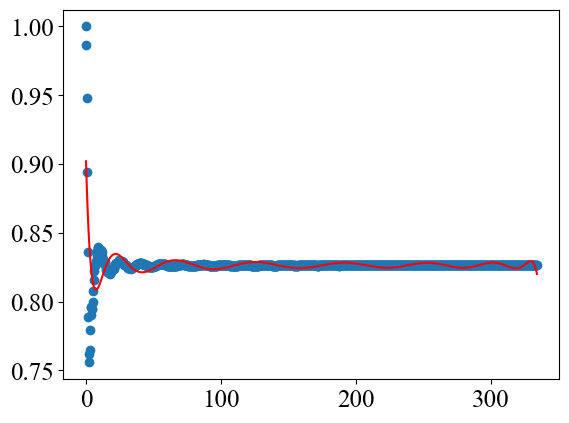

In [42]:
x = t_list
y = np.real(A_list[:, 1, 1])

coefficients = np.polyfit(x, y, 15)
polynomial = np.poly1d(coefficients)

plt.scatter(x, y)
plt.plot(x, polynomial(x), color='red')
plt.show()

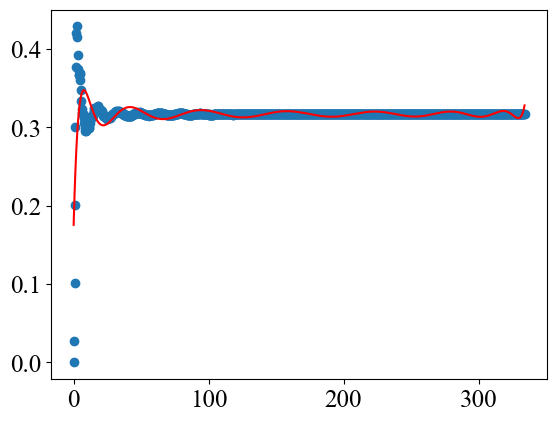

In [43]:
x = t_list
y = np.real(A_list[:, 0, 3])

coefficients = np.polyfit(x, y, 15)
polynomial = np.poly1d(coefficients)

plt.scatter(x, y)
plt.plot(x, polynomial(x), color='red')
plt.show()

In [18]:
from scipy.integrate import cumulative_simpson

pauli_list = np.array([np.array([[0, 1], [1, 0]]), np.array([[0, -1j], [1j, 0]]), np.array([[1, 0], [0, -1]])])
t_step = t_list[1] - t_list[0]

F_list = []
for t in range(len(t_list)):
	F = np.zeros((3, 3), dtype=np.complex128)
	for i, a in enumerate(pauli_list):
		for j, b in enumerate(pauli_list):
			F[i, j] = np.trace(a @ np.reshape(A_list[t] @ b.flatten(), (2, 2))) / 2
	F_list.append(F)

F_det_list = [abs(np.linalg.det(F)) for F in F_list]
F_det_grad_list = np.gradient(F_det_list, t_step, edge_order=2)
cumulative_simpson(np.clip(F_det_grad_list, a_min=0, a_max=np.inf), dx=t_step)[-1]

np.float64(0.22308856883520234)

In [19]:
FF_list = np.abs(model.f_list) ** 4
dFF_list = np.gradient(FF_list, t_step, edge_order=2)
cumulative_simpson(np.clip(dFF_list, a_min=0, a_max=np.inf), dx=t_step)[-1]

np.float64(0.22308856883520284)